In [1]:
#Benjamin Wollant
#October 4th, 2024
#This Juptyer Notebook is to develop a template for the full data processing pipeline for bead tracking.
#Given input tiff movies, it will localize beads, track individual beads, and calculate diffusion coefficients for beads
#Will use this to figure out how to best determine bound nanoswitches, then clean up and create a template

#Notes:
#20x objective w/ Hamamatsu is 320 nm/pixel

In [258]:
import numpy as np
import matplotlib.pyplot as plt
import threading
import pickle
from matplotlib.backends.backend_pdf import PdfPages
from typing import List, Tuple, Optional, Dict, Any
from bead_analysis import BigMovie
from identify_particles import identify_particles
from track_particles import find_particle_center_single_frame
from diffusion import calculate_diffusion_coefficient_trace
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
import time
import cv2
from scipy.spatial.distance import pdist, squareform

def load_files(folder: str, filebase: str, extensions: List[str]) -> List[str]:
    """
    Load file paths for the given folder and filebase with different extensions.

    Parameters:
    - folder: Directory path containing the TIFF files.
    - filebase: Base name for the TIFF files.
    - extensions: List of file extensions for different parts of the video.

    Returns:
    - List of complete file paths for the TIFF files.
    """
    return [os.path.join(folder, filebase + ext) for ext in extensions]


def filter_close_particles(particles: List[Any], min_distance: float = 20.0) -> List[Any]:
    """
    Filter out particles that are too close to each other based on a given minimum distance.

    Parameters:
    - particles: List of particle objects with a `centroid` attribute.
    - min_distance: Minimum allowable distance between particles.

    Returns:
    - filtered_particles: List of particles with close particles removed.
    """
    if not particles:
        return []

    # Extract the (x, y) coordinates from each particle's centroid
    centroids = np.array([p.centroid for p in particles])

    # Compute the pairwise distances between centroids
    dist_matrix = squareform(pdist(centroids))  # Create a symmetric distance matrix

    # Create a boolean mask to mark particles to keep
    to_keep = np.ones(len(particles), dtype=bool)

    # Iterate through the distance matrix and mark close particles for removal
    for i in range(len(particles)):
        if to_keep[i]:
            # Mark particles that are too close to the current particle
            close_particles = (dist_matrix[i] < min_distance) & (dist_matrix[i] > 0)
            to_keep[np.where(close_particles)[0]] = False

    # Return the filtered list of particles
    filtered_particles = [p for i, p in enumerate(particles) if to_keep[i]]
    return filtered_particles


def localize_particles(file: str, ncal_frames: int = 10, min_particle_area: int = 50,
                       max_particle_area: int = 100, border: int = 50, min_distance: float = 20.0) -> Tuple[List[Any], np.ndarray]:
    """
    Localize particles in the initial frames and perform initial filtering using BigMovie.

    Parameters:
    - file: The path to the TIFF file.
    - ncal_frames: Number of frames to use for calibration.
    - min_particle_area: Minimum area for a valid particle.
    - max_particle_area: Maximum area for a valid particle.
    - border: Distance from the image edge to exclude particles.

    Returns:
    - particles: List of particle objects.
    - initial_frame: First frame of the TIFF file for visualization.
    """
    movie = BigMovie(file)  # Use BigMovie to read the TIFF file
    frames = [next(movie) for _ in range(ncal_frames)]  # Extract first `ncal_frames` frames
    height, width = frames[0].shape

    # Identify particles in each frame and select the frame with the fewest particles
    particles, num_particles = [], 10000
    for frame in frames:
        current_particles = identify_particles(frame, min_particle_area=min_particle_area,
                                               max_particle_area=max_particle_area)
        if len(current_particles) < num_particles:
            particles = current_particles
            num_particles = len(current_particles)

    # Filter out particles that are too close to the edge of the image
    particles = [p for p in particles if
                 border < p.centroid[0] < width - border and border < p.centroid[1] < height - border]
    
    particles = filter_close_particles(particles, min_distance = min_distance)
    return particles, frames[0]  # Return particles and the initial frame for QC visualization


def track_particles(flist: List[str], particles: List[Any], crop_size: int = 12) -> np.ndarray:
    """
    Track particles across multiple TIFF files using the BigMovie class and threading to parallelize processing of single videos.

    Parameters:
    - flist: List of TIFF file paths.
    - particles: Initial particle objects identified.
    - crop_size: Size of the window around each particle for tracking.

    Returns:
    - trajectories: A 3D numpy array of shape (num_particles, total_frames, 2) for particle trajectories.
    """
    num_particles = len(particles)
    total_frames = 0

    # Calculate frames per video file and the total number of frames
    frames_per_video = []
    for file in flist:
        frame_count = sum(1 for _ in BigMovie(file))
        frames_per_video.append(frame_count)
        total_frames += frame_count

    # Preallocate array for trajectories for the whole video series
    trajectories = np.empty((num_particles, total_frames, 2))

    # Function to process frames in a single video file and update trajectories
    def process_movie(file: str, fnum: int) -> None:
        movie = BigMovie(file)
        frame_index = sum(frames_per_video[:fnum])  # Calculate starting index for this file

        for frame in movie:
            for p in range(num_particles):
                # Crop stack for each particle based on its centroid
                y_cent, x_cent = map(int, particles[p].centroid)  # Get rounded centroid coordinates
                cropped_frame = frame[y_cent - crop_size: y_cent + crop_size, x_cent - crop_size: x_cent + crop_size]
                center = find_particle_center_single_frame(cropped_frame)
                trajectories[p][frame_index] = center
            frame_index += 1
            
        # Print the number of active threads
        print(f"File {file} is processed. Active Threads: {threading.active_count()}")

    # Use ThreadPoolExecutor for threading
    with ThreadPoolExecutor(max_workers=len(flist)) as executor:
        futures = {executor.submit(process_movie, file, fnum): file for fnum, file in enumerate(flist)}

        # Optional: Monitor progress
        for future in as_completed(futures):
            file = futures[future]
            try:
                future.result()
                print(f"Completed tracking for file: {file}")
            except Exception as exc:
                print(f"File {file} generated an exception: {exc}")

    return trajectories



def drift_correction(trajectories: np.ndarray) -> np.ndarray:
    """
    Apply drift correction to the particle trajectories.

    Parameters:
    - trajectories: Raw particle trajectories.

    Returns:
    - corrected_trajectories: Drift-corrected trajectories.
    """
    # correct for total drift by taking mean of all particles in each frame
    trajectories_mean = np.mean(trajectories, axis=0)
    corrected_trajectories = trajectories - trajectories_mean
    
    # center each particle about its own, drift-corrected mean
    particle_mean = np.mean(corrected_trajectories, axis=1)
    return corrected_trajectories - particle_mean[:, np.newaxis, :]


def calculate_diffusion_coefficients(trajectories: np.ndarray, dt: float, window_size: int=60,) -> np.ndarray:
    """
    Calculate the diffusion coefficients for the given trajectories.

    Parameters:
    - trajectories: 3D array of particle trajectories.
    - dt: duration of each frame
    - window in over which diffusion is calcualted

    Returns:
    - diffusion_coefficients: 1D array of diffusion coefficients.
    """
    return np.array([calculate_diffusion_coefficient_trace(traj[:, 0], traj[:, 1], dt = dt, window_size=window_size) for traj in trajectories])


def calculate_fraction_bound(diffusion_coeffs: np.ndarray, threshold: float):
    
    # Compare each value in the array with the threshold, resulting in a boolean array
    below_threshold = diffusion_coeffs < threshold
    
    # Sum along the particle axis (axis=0) to count how many values are below the threshold at each time point
    count_below = np.sum(below_threshold, axis=0)
    
    # Normalize
    total_particles = diffusion_coeffs.shape[0]
    normalized_count = count_below / total_particles

    return normalized_count


def save_tracking_data(data: Tuple[np.ndarray, np.ndarray], filename: str) -> None:
    """
    Save tracking data to a pickle file.

    Parameters:
    - data: Tuple of corrected trajectories and diffusion coefficients.
    - filename: Name of the output pickle file.
    """
    with open(filename, 'wb') as file:
        pickle.dump(data, file)



# Visualization functions
def plot_particle_size_histogram(particles):
    sizes = []
    for p in particles:
        sizes.append(p.area)
    plt.hist(sizes, bins=20, edgecolor='black')  # You can adjust the number of bins as needed
    
    # Add labels and title
    plt.xlabel('Size (pixels)')
    plt.ylabel('Frequency')
    plt.title('Particle Size')
    
    plt.show()

def display_identified_particles(particles, localization_frame, particle_num: bool=True):
    localized_image = localization_frame.copy()

    for idx, p in enumerate(particles):
        # Extract the bounding box coordinates and draw rectangles around the particles
        minr, minc, maxr, maxc = p.bbox
        cv2.rectangle(localized_image, (minc - 5, minr - 5), (maxc + 5, maxr + 5), (0, 255, 0), 2)
        if particle_num:
            cv2.putText(localized_image, str(idx), (minc - 10, minr - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        
    # Display the image with bounding boxes
    plt.figure(figsize=(10, 10))
    plt.imshow(localized_image, cmap='gray')
    plt.title("Identified Particles with Bounding Boxes")
    plt.show()
    
    
def plot_particle_trajectories(trajectories: np.ndarray, diffusion_coeffs: np.ndarray, pdf_name: str, frame_length: float = 30e-3, xy_max: float = 400.0) -> None:
    """
    Plot and save tracking results and diffusion coefficients.

    Parameters:
    - trajectories: 3D array of particle trajectories.
    - diffusion_coeffs: 1D array of diffusion coefficients.
    - pdf_name: Name of the output PDF file.
    - frame_length: acquisition time per frame in seconds.
    - xy_max: limit (+/-) on x and y position axes.
    """
    pdf_pages = PdfPages(pdf_name)

    # Create a histogram of diffusion coefficients
    diff_coeffs_mean = np.mean(diffusion_coeffs, axis=1)
    plt.hist(diff_coeffs_mean, bins=np.arange(0, 0.5, 0.01), edgecolor='black', alpha=0.7)
    plt.xlabel('D (um^2/s)')
    plt.ylabel('Frequency')
    plt.title('Diffusion Coefficient Distribution')
    pdf_pages.savefig()
    plt.close()


    # Traces for Particles Positions
    for particle_index, trajectory in enumerate(trajectories): 
        x_positions = trajectory[:, 0]
        y_positions = trajectory[:, 1]
        
        t = np.array(range(0, len(x_positions))) * frame_length
    
        fig, axs = plt.subplots(3, 1, figsize=(40, 20), sharex=True)
        
        # Remove horizontal space between axes
        fig.subplots_adjust(hspace=0.1)
        
        # Plot x(t) on the first subplot
        axs[0].plot(t, x_positions, label='x(t)', color='darkorange')
        axs[0].set_ylabel('x position (nm)', fontweight='bold')
        axs[0].set_title(
            f'Particle {particle_index} Position Over Time',
            fontweight='bold', fontsize=16)
        axs[0].grid(True)
        axs[0].ticklabel_format(useOffset=False)
        axs[0].set_ylim(-xy_max,xy_max)
        
        # Plot y(t) on the second subplot
        axs[1].plot(t, y_positions, label='y(t)', color='mediumblue')
        axs[1].set_ylabel('y position (nm)', fontweight='bold')
        axs[1].grid(True)
        axs[1].ticklabel_format(useOffset=False)
        axs[1].set_ylim(-xy_max,xy_max)
    
        
        plt.xlabel('Time (s)', fontweight='bold')
        
        plt.xticks(fontsize=12, fontweight='bold')  # Increase X-axis tick label font size
        plt.yticks(fontsize=12, fontweight='bold') 
        
        # Plot D(t) on the third subplot
        axs[2].plot(t, diffusion_coeffs[particle_index], label='D(t)', color='green')
        axs[2].set_ylabel('D(t) (um^2/s)', fontweight='bold')
        axs[2].grid(True)
        axs[2].ticklabel_format(useOffset=False)
        axs[2].set_ylim(0,0.4)
        
        # Save the current figure to the PDF
        pdf_pages.savefig(fig)
        
        # Explicitly close the figure to avoid memory overflow
        plt.close(fig)

    pdf_pages.close()
    
    
def plot_fraction_bound(fraction_bound: np.ndarray, threshold: float, pdf_name: str, frame_length: float = 30e-3) -> None:
    """
    Plot and save the fraction of nanoswitches bound over time based on a threshold value for the coefficient of diffusion. 

    Parameters:
    - trajectories: 3D array of particle trajectories.
    - diffusion_coeffs: 1D array of diffusion coefficients.
    - pdf_name: Name of the output PDF file.
    - frame_length: acquisition time per frame in seconds.
    - xy_max: limit (+/-) on x and y position axes.
    """
    pdf_pages = PdfPages(pdf_name)
    
    # Create the figure and axis
    fig, ax = plt.subplots(figsize=(10, 6))
    
    time_points = np.arange(fraction_bound.shape[0])*frame_length
    plt.plot(time_points, fraction_bound, marker='o')
    plt.xlabel('time')
    plt.ylabel(f'Fraction of Particles Below D = {threshold} (um^2/s)')
    plt.title('Fraction of NS Particles Bound')
    plt.grid(True)
    
    pdf_pages.savefig(fig)
    plt.close(fig)
    pdf_pages.close()

    


In [0]:
# Code blocks for running analysis
    

In [281]:
# File Path Specification
folder = '/Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1'
filebase = '240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0'
extensions = ['.ome.tif', '_1.ome.tif', '_2.ome.tif', '_3.ome.tif']
pdf_name = '240522_FullPass_NS_MAGz9_motion_7191_875um_trial.pdf'
pickle_file = '240522_noMAG.pkl'

# Constants
nm_per_pixel = 320 # 320 for Hammamatsu in Dunn lab, not sure for Nikon setup 
frame_length = 0.030 # length of frame acquisition in s
D_cutoff = 0.1 # cutoff for bound (below) vs unbound (above) (um^2/s)
    

In [273]:
# Load files
print("Creating flist...")
start_time = time.time()
flist = load_files(folder, filebase, extensions)
end_time = time.time()
print(f"flist created in {end_time - start_time}s.")
    

Creating flist...
flist created in 0.0005681514739990234s.


In [274]:
# Localize particles
print("Localizing particles...")
start_time = time.time()
particles, localization_frame = localize_particles(flist[0], ncal_frames= 10, min_particle_area=50, max_particle_area=100, border=50, min_distance=20)
end_time = time.time()
print(f"Particles localized in {end_time - start_time}s.")

Localizing particles...
Particles localized in 30.894341945648193s.


In [249]:
# plot particle size histogram
#plot_particle_size_histogram(particles)


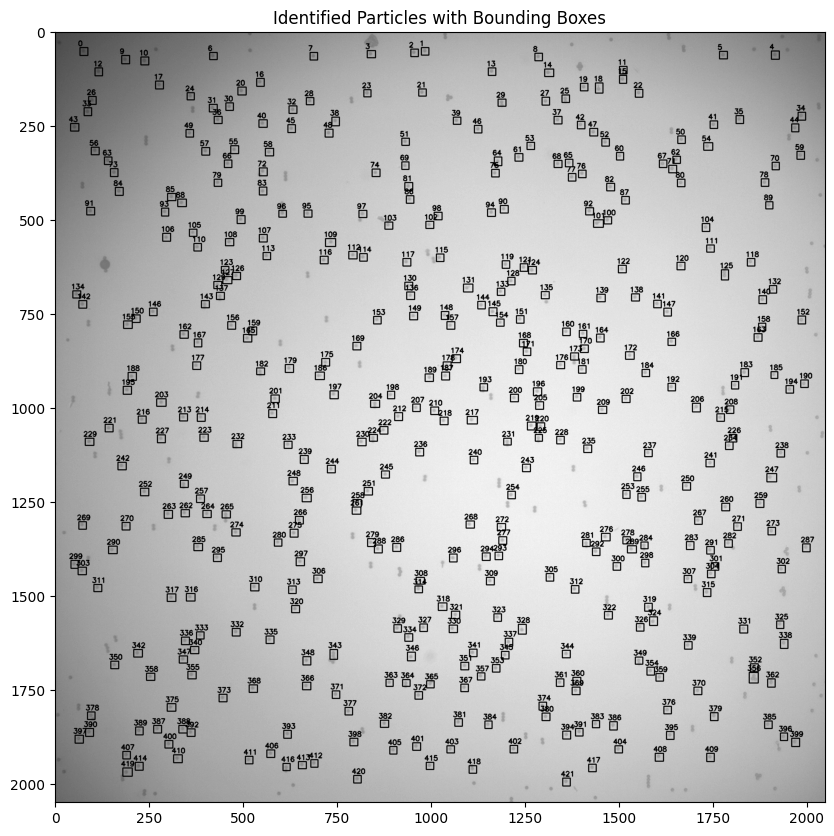

In [275]:
# display localized particles

display_identified_particles(particles, localization_frame, particle_num=True)


In [276]:
# Track particles- output in pixels
print("Calculating trajectories...")
start_time = time.time()
trajectories = track_particles(flist, particles, crop_size=12)
end_time = time.time()
print(f"Trajectories calculated in {end_time - start_time}s.")

Calculating trajectories...


/Users/Benj/PycharmProjects/MagneticActuationTracking/radialcenter.py:53: RuntimeWarning: divide by zero encountered in divide
  m = -(fdv+fdu)/(fdu-fdv)  # deleted a minus sign here 8/21/2023 for images with dark particles- now replaced, should not matter
/Users/Benj/PycharmProjects/MagneticActuationTracking/radialcenter.py:53: RuntimeWarning: invalid value encountered in divide
  m = -(fdv+fdu)/(fdu-fdv)  # deleted a minus sign here 8/21/2023 for images with dark particles- now replaced, should not matter
/Users/Benj/PycharmProjects/MagneticActuationTracking/radialcenter.py:58: RuntimeWarning: divide by zero encountered in divide
  unsmoothm = (dIdv + dIdu)/(dIdu - dIdv)
/Users/Benj/PycharmProjects/MagneticActuationTracking/radialcenter.py:58: RuntimeWarning: invalid value encountered in divide
  unsmoothm = (dIdv + dIdu)/(dIdu - dIdv)


File /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_3.ome.tif is processed. Active Threads: 13
Completed tracking for file: /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_3.ome.tif
File /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_2.ome.tif is processed. Active Threads: 13
Completed tracking for file: /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_2.ome.tif
File /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_1.ome.tif is processed. Active Threads: 13
Completed tracking for file: /Volumes/T7/240522/240522_FullPass_NS_MAGz9_motion_7191_875um_1/240522_FullPass_NS_MAGz9_motion_7191_875um_1_MMStack_Pos0_1.ome.tif
File /V

In [277]:
# Apply drift correction and conversion to nm
print("Correcting drift...")
start_time = time.time()
corrected_trajectories = nm_per_pixel*drift_correction(trajectories)
end_time = time.time()
print(f"Drift corrected in {end_time - start_time}s.")

Correcting drift...
Drift corrected in 0.02549290657043457s.


In [278]:
# Calculate diffusion coefficients
print("Calculating diffusion coefficients...")
start_time = time.time()
diffusion_coeffs = calculate_diffusion_coefficients(corrected_trajectories, dt=frame_length)
end_time = time.time()
print(f"Diffusion coefficients calculated in {end_time - start_time}s.")


Calculating diffusion coefficients...
Diffusion coefficients calculated in 205.82117819786072s.


In [260]:
# Calculate the fraction bound over time
fraction_bound = calculate_fraction_bound(diffusion_coeffs=diffusion_coeffs, threshold=D_cutoff)

In [282]:
# Plot and save results for individual particles
plot_particle_trajectories(trajectories=corrected_trajectories, diffusion_coeffs=diffusion_coeffs, pdf_name=pdf_name, frame_length=frame_length, xy_max=400)


In [244]:
# Plot and save results for fraction bound
# need to adjust window for plotting to get rid of edge effects, threshold, etc....
plot_fraction_bound(fraction_bound=fraction_bound, threshold=D_cutoff, pdf_name=pdf_name, frame_length = frame_length)

In [32]:
# Save data to a file
#save_tracking_data((corrected_trajectories, diffusion_coeffs), pickle_file)


Calculating trajectories...


NameError: name 'particles' is not defined